# Recommending a gameplay genre from a Steam user's earlier reviews

Assignment 2 asks for a predictive task, an evaluation, and a baseline the model has to beat. This notebook uses the Steam Dataset 2025. For each user with enough history, the task is to name **one gameplay genre**. The name is a hit when that genre is on the user's latest review of a game.

A game can carry several gameplay genres. The model still names one of them. The nine names it may recommend are Action, Adventure, Casual, Massively Multiplayer, Racing, RPG, Simulation, Sports, and Strategy. Indie, Free to Play, and Early Access stay in the features. Content descriptors and software genres are counted in the exploratory section and left out of the label.

**Source.** Donald Fountain, *The Steam Dataset 2025* (Zenodo, [10.5281/zenodo.17286923](https://doi.org/10.5281/zenodo.17286923)). The CSV package in `data/archive/steam_dataset_2025_csv` is the same release posted on Kaggle. It was collected from Valve's store and review APIs between 31 August and 29 September 2025, with about ten reviews stored per application. The dataset license is CC BY 4.0.

**Evaluation.** The primary protocol holds out each eligible user's latest game review that has a gameplay genre, and it builds features only from earlier reviews. Hit rate is the primary metric. Per-genre recall keeps Action from hiding a miss on Racing or Sports. Mean Jaccard compares the one predicted genre with the game's full gameplay-genre set, so a hit on a game that has three gameplay genres scores one third. Results are sliced by history length: 1 earlier review, 2–4, and 5 or more. Two other protocols sit next to the primary one. A random per-user holdout may use reviews written on the other side of the held-out review. A calendar cutoff keeps the 80th percentile of review time.

**Baselines.** Global mode names the gameplay genre that appears on the most training reviews. User mode names the gameplay genre that appears most often in that user's own training reviews. Ties in the global count use the genre order written below. Ties in a user's count use the global ranking. The prototype is a one-vs-rest logistic regression on the mix of genres in the history.

**Sample.** The median user appears once, because reviews were drawn per application. A personalized score exists only for users whose sample contains a gameplay-genre review and an earlier review of a game. `steam_purchase` is checked below; in this file it does not vary, so it is not a feature.

Run this notebook with the working directory set to the repository root.


In [1]:
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from implicit.bpr import BayesianPersonalizedRanking
from scipy.sparse import csr_matrix

pd.set_option("display.max_rows", 30)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
})

ROOT = Path.cwd()
DATA = ROOT / "data" / "archive" / "steam_dataset_2025_csv"
NOTES = ROOT / "cursor_notes"
NOTES.mkdir(exist_ok=True)
assert DATA.exists(), f"Expected the CSV package at {DATA}"

GAMEPLAY = [
    "Action",
    "Adventure",
    "Casual",
    "Massively Multiplayer",
    "Racing",
    "RPG",
    "Simulation",
    "Sports",
    "Strategy",
]
GAMEPLAY_INDEX = {name: i for i, name in enumerate(GAMEPLAY)}
STORE_LABELS = ("Indie", "Free to Play", "Early Access")
FEATURE_NAMES = list(GAMEPLAY) + [
    "indie_rate",
    "free_to_play_rate",
    "early_access_rate",
    "log_playtime",
    "voted_up_rate",
    "log_history_len",
    "log_library_size",
]

# Raw Steam genre name -> canonical bucket. The reasons for the less obvious
# rows are written to cursor_notes/genre_lexicon.md when this cell runs.
GENRE_MAP = {
    "Aventură": "Adventure",
    "Многопользовательские игры": "Massively Multiplayer",
    "Nezávislé": "Indie",
    "Strategie": "Strategy",
    "Strategy": "Strategy",
    "Acțiune": "Action",
    "インディー": "Indie",
    "アクション": "Action",
    "Acesso Antecipado": "Early Access",
    "Simulaatio": "Simulation",
    "Simulation": "Simulation",
    "Sexual Content": "content_flag",
    "Azione": "Action",
    "Aksiyon": "Action",
    "Racing": "Racing",
    "Massively Multiplayer": "Massively Multiplayer",
    "Simuladores": "Simulation",
    "Eventyr": "Adventure",
    "MMO": "Massively Multiplayer",
    "Szimuláció": "Simulation",
    "Бесплатные": "Free to Play",
    "Akcja": "Action",
    "Episodic": "unmapped",
    "Bağımsız Yapımcı": "Indie",
    "Multijogador Massivo": "Massively Multiplayer",
    "Petualangan": "Adventure",
    "Web Publishing": "software",
    "Gratis at spille": "Free to Play",
    "Basit Eğlence": "Casual",
    "Stratégie": "Strategy",
    "Indie": "Indie",
    "Casual": "Casual",
    "Documentary": "unmapped",
    "Kasual": "Casual",
    "Rekreacyjne": "Casual",
    "Gratuitos para Jogar": "Free to Play",
    "Simulação": "Simulation",
    "Bildung": "software",
    "Abenteuer": "Adventure",
    "Rollespill": "RPG",
    "Симулятори": "Simulation",
    "Avventura": "Adventure",
    "Пригоди": "Adventure",
    "Free To Play": "Free to Play",
    "Animation & Modeling": "software",
    "Estratégia": "Strategy",
    "Design & Illustration": "software",
    "獨立製作": "Indie",
    "Nudity": "content_flag",
    "Software Training": "software",
    "Rollenspiel": "RPG",
    "休閒": "Casual",
    "Photo Editing": "software",
    "Aventura": "Adventure",
    "Masivně multiplayerové": "Massively Multiplayer",
    "ストラテジー": "Strategy",
    "Macera": "Adventure",
    "Devasa Çok Oyunculu": "Massively Multiplayer",
    "Multigiocatore di massa": "Massively Multiplayer",
    "Sport": "Sports",
    "Aventure": "Adventure",
    "Sports": "Sports",
    "Гонки": "Racing",
    "Ação": "Action",
    "Rol": "RPG",
    "Corrida": "Racing",
    "Simulatoare": "Simulation",
    "Audio Production": "software",
    "Рольові ігри": "RPG",
    "Stratégia": "Strategy",
    "Симуляторы": "Simulation",
    "独立": "Indie",
    "Corse": "Racing",
    "Rennspiele": "Racing",
    "免费开玩": "Free to Play",
    "Indépendant": "Indie",
    "Esportes": "Sports",
    "Strategické": "Strategy",
    "Gore": "content_flag",
    "动作": "Action",
    "Accounting": "software",
    "Tutorial": "unmapped",
    "Video Production": "software",
    "策略": "Strategy",
    "Äventyr": "Adventure",
    "Spieleentwicklung": "software",
    "模拟": "Simulation",
    "Strateji": "Strategy",
    "Spor": "Sports",
    "Неангажиращи": "Casual",
    "Simulatie": "Simulation",
    "カジュアル": "Casual",
    "Free to Play": "Free to Play",
    "冒險": "Adventure",
    "Gratis te spelen": "Free to Play",
    "Інді": "Indie",
    "体育": "Sports",
    "Web-Publishing": "software",
    "Simülasyon": "Simulation",
    "RYO": "RPG",
    "アドベンチャー": "Adventure",
    "Strategi": "Strategy",
    "Симулатори": "Simulation",
    "Sportowe": "Sports",
    "Стратегии": "Strategy",
    "Violent": "content_flag",
    "Early Access": "Early Access",
    "Przygodowe": "Adventure",
    "Simulering": "Simulation",
    "Gelegenheitsspiele": "Casual",
    "Sportovní": "Sports",
    "Стратегії": "Strategy",
    "Adventure": "Adventure",
    "Simulasi": "Simulation",
    "Независими": "Indie",
    "Utilities": "software",
    "Gratis att spela": "Free to Play",
    "Strategia": "Strategy",
    "Ролевые игры": "RPG",
    "Acción": "Action",
    "Перегони": "Racing",
    "Action": "Action",
    "Game Development": "software",
    "角色扮演": "RPG",
    "Экшены": "Action",
    "Niezależne": "Indie",
    "Passatempo": "Casual",
    "Приключенческие игры": "Adventure",
    "Deportes": "Sports",
    "Education": "software",
    "Movie": "unmapped",
    "Dobrodružné": "Adventure",
    "Бойовики": "Action",
    "360 Video": "unmapped",
    "Fritid": "Casual",
    "Aksi": "Action",
    "Simulátory": "Simulation",
    "Simuleringar": "Simulation",
    "Estrategia": "Strategy",
    "Спорт": "Sports",
    "Simulationen": "Simulation",
    "動作": "Action",
    "Simulazione": "Simulation",
    "RPG": "RPG",
    "Actie": "Action",
    "Инди": "Indie",
    "Symulacje": "Simulation",
    "Multijugador masivo": "Massively Multiplayer",
    "竞速": "Racing",
    "冒险": "Adventure",
    "Short": "unmapped",
    "إثارة": "unmapped",
    "Akció": "Action",
    "مجانية": "Free to Play",
}

LEXICON_RATIONALE = """
The Steam genre table repeats the same store genres in many languages. Each of the 154 raw names is sent to one bucket.

Gameplay labels, the nine a recommendation may name: Action, Adventure, Casual, Massively Multiplayer, Racing, RPG, Simulation, Sports, Strategy.

Store labels, used as features and not as recommendations: Indie, Free to Play, Early Access.

Content descriptors, counted in EDA and then dropped: Sexual Content, Nudity, Gore, Violent.

Software genres, counted and then dropped: Accounting, Animation & Modeling, Audio Production, Design & Illustration, Education (the German row Bildung is Education), Game Development (the German row Spieleentwicklung is Game Development), Photo Editing, Software Training, Utilities, Video Production, Web Publishing, and Web-Publishing.

Left unmapped, because they are not Steam store genres: Documentary, Episodic, Movie, Short, Tutorial, 360 Video, and Arabic إثارة ("thriller" / "excitement"). Counter-Strike 2 is tagged only with إثارة and مجانية in this file, so that game has no gameplay genre and cannot be a label. مجانية is Arabic for "free" and is mapped to Free to Play.

Ambiguous calls:

- Многопользовательские игры is Russian for "multiplayer games". All 9 rows are DLC for the online shooter Caliber, and those rows are also tagged Экшены (Action) and Бесплатные (Free to Play). That pairing is the usual Steam triple of Action, Massively Multiplayer, and Free to Play, so the string is mapped to Massively Multiplayer rather than left as its own class.
- RYO is the Japanese abbreviation of RPG. Rol is the Spanish and Portuguese store name for RPG. Jade's Journey is tagged Rol together with Aventura and Estrategia. Both names map to RPG.
- Бесплатные is the short Russian form of Free to Play, on the same Caliber rows as the multiplayer string.
- Sport, Spor, and the other singular translations map to Sports.

A translated store genre is mapped onto that genre. It is not left unmapped. Counts below are game applications carrying the raw name, after the type filter. Most translations are rare. The English rows carry almost all of the links.
""".strip()


c:\Users\Young\anaconda3\envs\dsc256\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load, lexicon, and the modeling table

Reviews are kept when the application type is `game`. A repeated (user, app) pair keeps the later timestamp. Each raw genre name is replaced with the bucket in `GENRE_MAP`. A game's gameplay genres collapse to a set, so `Action` and `アクション` on the same title count once.

A review can be a label only when its game has at least one of the nine gameplay genres. Earlier reviews of games that have only Indie, Free to Play, Early Access, a software genre, or no genre still sit in the history. Playtimes are left as stored. The model uses `log1p` of the mean, so the extreme tail (several million minutes) does not have to be deleted to keep the feature finite.

The Russian multiplayer string is mapped to Massively Multiplayer, `RYO` and `Rol` to RPG, and Arabic إثارة is left unmapped. The full name-by-name list, with those calls, is written to `cursor_notes/genre_lexicon.md`.


In [2]:
genres = pd.read_csv(DATA / "genres.csv")
missing = sorted(set(genres["name"]) - set(GENRE_MAP))
extra = sorted(set(GENRE_MAP) - set(genres["name"]))
assert not missing, missing
assert not extra, extra
assert genres["name"].is_unique
genres["canon"] = genres["name"].map(GENRE_MAP)

apps = pd.read_csv(DATA / "applications.csv", usecols=["appid", "type"])
game_ids = set(apps.loc[apps["type"].eq("game"), "appid"].tolist())
app_genres = pd.read_csv(DATA / "application_genres.csv")
app_genres = app_genres.merge(genres[["id", "name", "canon"]], left_on="genre_id", right_on="id", how="left")
assert app_genres["canon"].notna().all()
game_links = app_genres.loc[app_genres["appid"].isin(game_ids), ["appid", "name", "canon"]].copy()

mask_d = defaultdict(int)
indie_d = defaultdict(int)
ftp_d = defaultdict(int)
early_d = defaultdict(int)
other_d = defaultdict(int)
for appid, canon in zip(game_links["appid"].to_numpy(), game_links["canon"].to_numpy()):
    appid = int(appid)
    if canon in GAMEPLAY_INDEX:
        mask_d[appid] |= 1 << GAMEPLAY_INDEX[canon]
    elif canon == "Indie":
        indie_d[appid] = 1
    elif canon == "Free to Play":
        ftp_d[appid] = 1
    elif canon == "Early Access":
        early_d[appid] = 1
    else:
        other_d[appid] = 1

linked_ids = set(mask_d) | set(indie_d) | set(ftp_d) | set(early_d) | set(other_d)
n_store_only = sum(
    1
    for appid in linked_ids
    if mask_d[appid] == 0 and other_d[appid] == 0 and (indie_d[appid] or ftp_d[appid] or early_d[appid])
)
n_other_only = sum(
    1
    for appid in linked_ids
    if mask_d[appid] == 0 and other_d[appid] == 1 and not (indie_d[appid] or ftp_d[appid] or early_d[appid])
)
n_with_gameplay = sum(1 for value in mask_d.values() if value)

name_counts = game_links.groupby("name").size().astype(int)
lexicon_lines = [
    "# Genre lexicon",
    "",
    LEXICON_RATIONALE,
    "",
    "Game-link counts are the number of `type = game` applications carrying that raw name.",
    "",
    "| Raw name | Bucket | Games |",
    "| --- | --- | ---: |",
]
for raw_name, canon in sorted(GENRE_MAP.items(), key=lambda item: (item[1], item[0])):
    lexicon_lines.append(f"| {raw_name} | {canon} | {int(name_counts.get(raw_name, 0))} |")
(NOTES / "genre_lexicon.md").write_text("\n".join(lexicon_lines) + "\n", encoding="utf-8")

lexicon_names = pd.Series(GENRE_MAP).value_counts()
bucket_order = ["content_flag", "software", "unmapped", "Indie", "Free to Play", "Early Access", *GAMEPLAY]
bucket_counts = pd.DataFrame({
    "names_in_lexicon": lexicon_names,
    "names_on_games": game_links.groupby("canon")["name"].nunique(),
    "genre_rows_on_games": game_links.groupby("canon").size(),
}).reindex(bucket_order).fillna(0).astype(int)
print(f"Mapped all {len(GENRE_MAP)} genre names. Wrote cursor_notes/genre_lexicon.md.")
print(
    f"Games in the catalog: {len(game_ids):,}. "
    f"Games with a genre link: {len(linked_ids):,}. "
    f"Games with a gameplay genre: {n_with_gameplay:,}. "
    f"Games whose only labels are Indie, Free to Play, or Early Access: {n_store_only:,}. "
    f"Games whose only labels are content flags, software, or unmapped names: {n_other_only:,}."
)
display(bucket_counts.rename_axis("bucket").reset_index())
print("names_in_lexicon counts every raw string in the map. names_on_games counts strings that appear on at least one game. Most translations are attached to DLC or to a handful of titles, so the second column is smaller.")

purchase = pd.read_csv(DATA / "reviews.csv", usecols=["steam_purchase"])
print(f"steam_purchase mean on all reviews: {purchase['steam_purchase'].mean():.4f}. The column is constant, so it is not loaded into the model.")
del purchase

review_cols = [
    "appid",
    "author_steamid",
    "author_num_games_owned",
    "author_playtime_at_review",
    "timestamp_created",
    "voted_up",
]
reviews = pd.read_csv(DATA / "reviews.csv", usecols=review_cols)
n_reviews_all = len(reviews)
n_users_all = reviews["author_steamid"].nunique()
work = reviews.loc[reviews["appid"].isin(game_ids)].copy()
n_game_reviews = len(work)
work = work.sort_values(["author_steamid", "appid", "timestamp_created"], kind="mergesort")
n_before_dedup = len(work)
work = work.drop_duplicates(["author_steamid", "appid"], keep="last")
n_deduped = len(work)

work["mask"] = work["appid"].map(mask_d).fillna(0).astype(np.int32)
work["indie"] = work["appid"].map(indie_d).fillna(0).astype(np.float64)
work["ftp"] = work["appid"].map(ftp_d).fillna(0).astype(np.float64)
work["early"] = work["appid"].map(early_d).fillna(0).astype(np.float64)
work["user_code"] = pd.factorize(work["author_steamid"], sort=False)[0].astype(np.int32)
work = work.sort_values(["user_code", "timestamp_created", "appid"], kind="mergesort").reset_index(drop=True)

masks = work["mask"].to_numpy(dtype=np.int32)
indie = work["indie"].to_numpy(dtype=np.float64)
ftp = work["ftp"].to_numpy(dtype=np.float64)
early = work["early"].to_numpy(dtype=np.float64)
ts = work["timestamp_created"].to_numpy(dtype=np.int64)
play = work["author_playtime_at_review"].to_numpy(dtype=np.float64)
voted = work["voted_up"].to_numpy(dtype=np.float64)
ngames = work["author_num_games_owned"].to_numpy(dtype=np.float64)
user_codes = work["user_code"].to_numpy(dtype=np.int32)
boundaries = np.flatnonzero(np.diff(user_codes)) + 1
starts = np.r_[0, boundaries]
ends = np.r_[boundaries, len(work)]

genre_mat = np.zeros((len(work), 9), dtype=np.float64)
for genre_i in range(9):
    genre_mat[:, genre_i] = (masks & (1 << genre_i)) != 0

n_label_reviews = int((masks != 0).sum())
n_temporal_users = 0
for start, end in zip(starts, ends):
    local_labels = np.flatnonzero(masks[start:end] != 0)
    if local_labels.size and int(local_labels[-1]) > 0:
        n_temporal_users += 1

funnel = pd.DataFrame([
    {"step": "Reviews in the file", "rows": n_reviews_all, "users": n_users_all},
    {"step": "Reviews of type = game", "rows": n_game_reviews, "users": np.nan},
    {"step": "After one row per user and game", "rows": n_deduped, "users": int(len(starts))},
    {"step": "Rows whose game has a gameplay genre", "rows": n_label_reviews, "users": np.nan},
    {"step": "Users eligible for the temporal holdout", "rows": np.nan, "users": n_temporal_users},
])
print(f"Repeated user-game rows removed: {n_before_dedup - n_deduped:,}.")
funnel_shown = funnel.copy()
for column in ("rows", "users"):
    funnel_shown[column] = funnel_shown[column].map(lambda value: "" if pd.isna(value) else f"{int(value):,}")
print(
    "Playtime at review (minutes), on the deduped game-review table: "
    f"median {np.nanmedian(play):.0f}, "
    f"p99 {np.nanpercentile(play, 99):.0f}, "
    f"max {np.nanmax(play):.0f}."
)
display(funnel_shown)


Mapped all 154 genre names. Wrote cursor_notes/genre_lexicon.md.
Games in the catalog: 150,279. Games with a genre link: 142,556. Games with a gameplay genre: 136,258. Games whose only labels are Indie, Free to Play, or Early Access: 4,616. Games whose only labels are content flags, software, or unmapped names: 1,268.


,bucket,names_in_lexicon,names_on_games,genre_rows_on_games
0,content_flag,4,4,924
1,software,14,11,4261
2,unmapped,7,7,8
3,Indie,11,8,101207
4,Free to Play,9,2,13725
5,Early Access,2,2,14605
6,Action,15,7,60444
7,Adventure,17,10,59030
8,Casual,10,5,58462
9,Massively Multiplayer,8,1,3649


names_in_lexicon counts every raw string in the map. names_on_games counts strings that appear on at least one game. Most translations are attached to DLC or to a handful of titles, so the second column is smaller.
steam_purchase mean on all reviews: 1.0000. The column is constant, so it is not loaded into the model.
Repeated user-game rows removed: 8.
Playtime at review (minutes), on the deduped game-review table: median 194, p99 22769, max 2030768.


,step,rows,users
0,Reviews in the file,"1,048,148","701,884"
1,Reviews of type = game,"865,782",
2,After one row per user and game,"865,774","600,542"
3,Rows whose game has a gameplay genre,"830,740",
4,Users eligible for the temporal holdout,,"86,110"


## What the catalog and the sample look like

The funnel above is the path from the raw review file to the users a temporal holdout can score. The plots below are on the deduped game-review table, except the catalog genre counts and the co-occurrence heatmap, which use every game in `applications.csv`.

The review file stores about ten reviews per application. It is a sample of public reviews, not a user's library and not the full review set of a game. Users reach the last row of the funnel only when at least two of their reviews fell into that sample, the later gameplay-genre review can be held out, and an earlier game review remains as history.


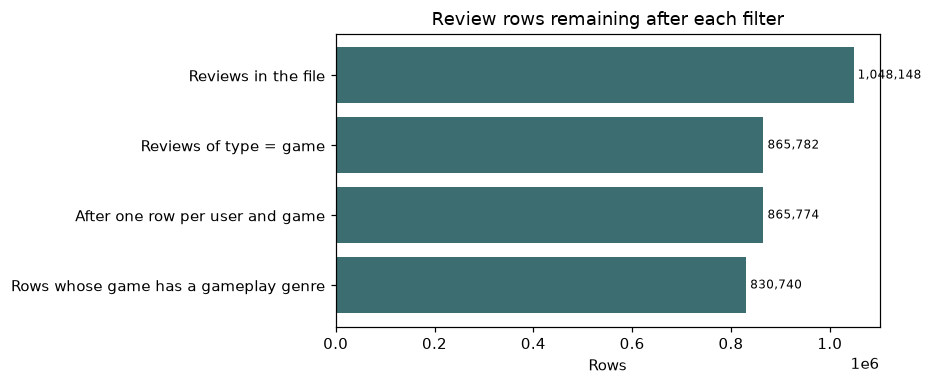

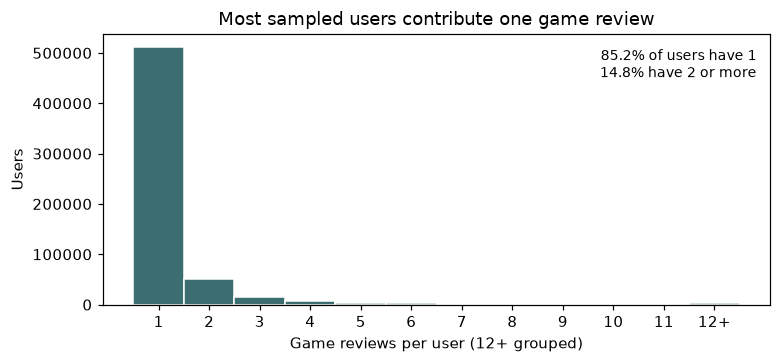

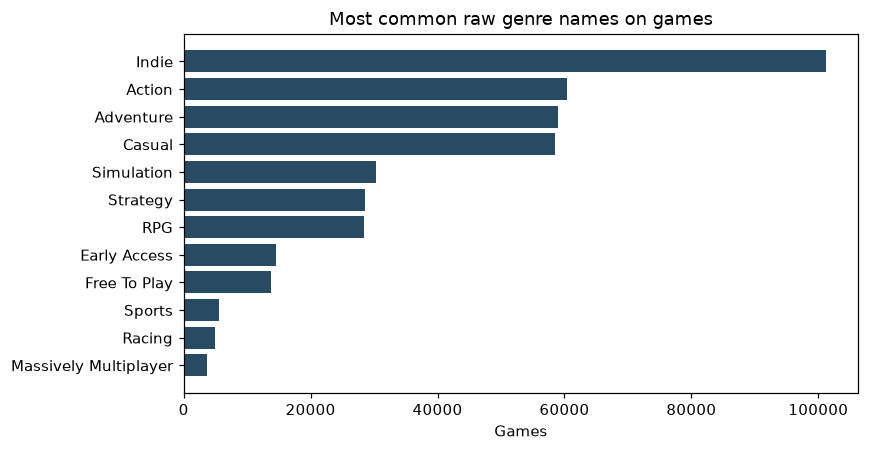

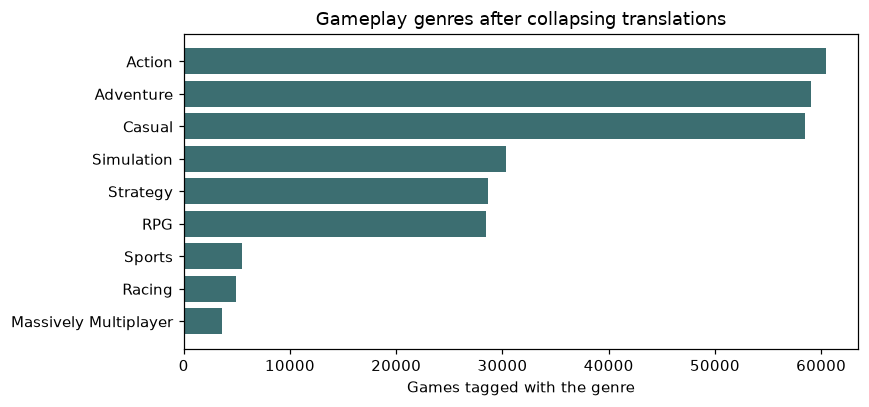

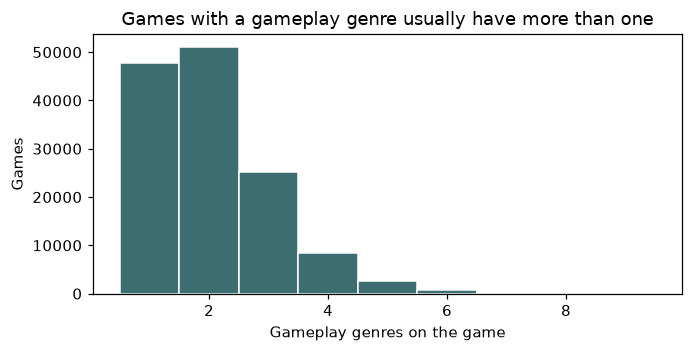

Share of gameplay-tagged games with 2 or more gameplay genres: 64.9%.


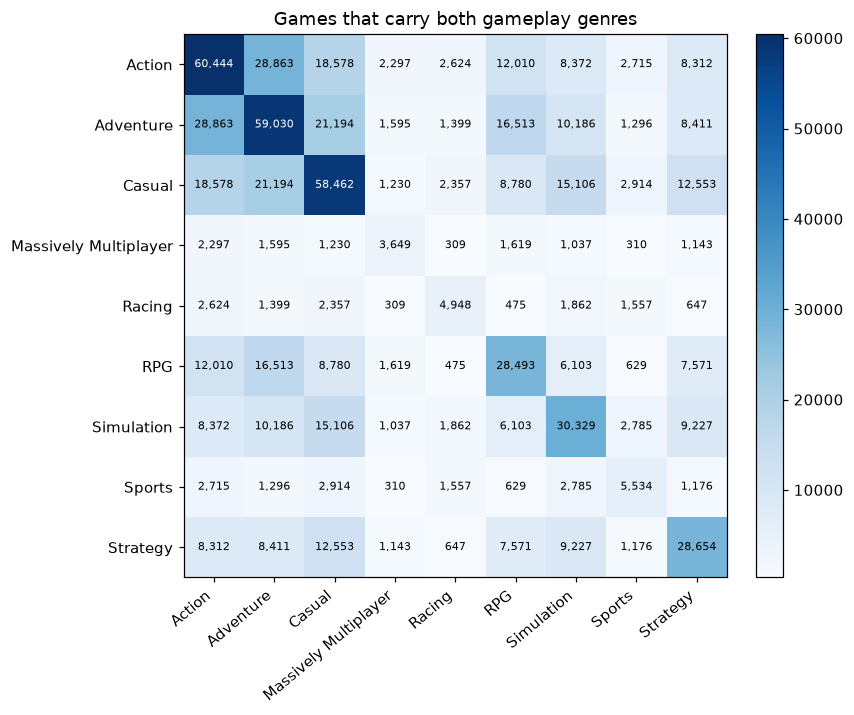

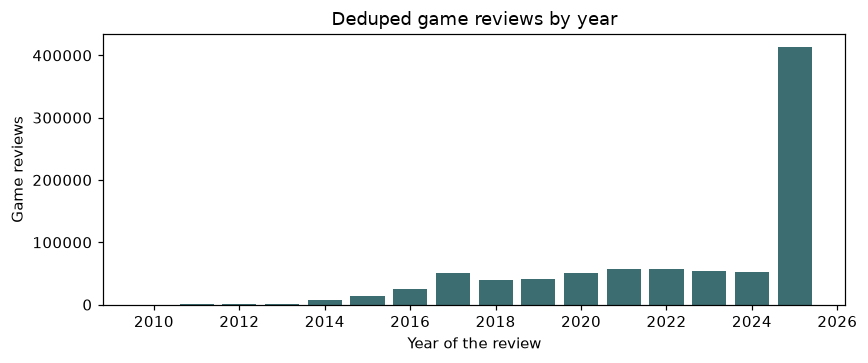

Share of deduped game reviews timestamped in 2025: 47.7%. That pile-up is why an 80th-percentile cutoff falls in the last weeks of the file.


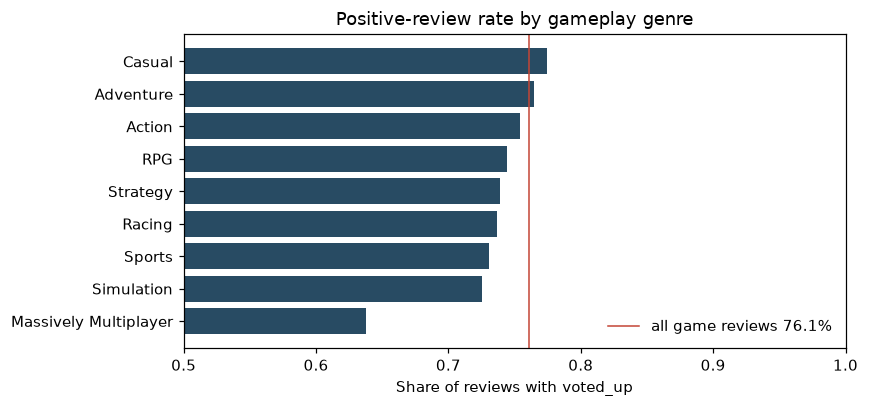

A review of a multi-genre game is counted in each of its gameplay genres.


,genre,reviews,voted_up_rate
0,Casual,300803,0.774809
1,Adventure,371111,0.764378
2,Action,387994,0.754305
3,RPG,191516,0.744335
4,Strategy,181590,0.738846
5,Racing,31517,0.736618
6,Sports,43076,0.730639
7,Simulation,217766,0.725407
8,Massively Multiplayer,23604,0.638070


In [3]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
funnel_plot = funnel.dropna(subset=["rows"])
ax.barh(funnel_plot["step"], funnel_plot["rows"], color="#3c6e71")
ax.invert_yaxis()
ax.set_xlabel("Rows")
ax.set_title("Review rows remaining after each filter")
for y_pos, value in enumerate(funnel_plot["rows"]):
    ax.text(value, y_pos, f" {int(value):,}", va="center", fontsize=8)
fig.tight_layout()
plt.show()

reviews_per_user = np.diff(np.r_[starts, len(work)])
# np.diff of starts concatenated with the length is the group size.
# ends already stores that. Recompute from ends - starts to be explicit.
reviews_per_user = ends - starts
capped = np.clip(reviews_per_user, 1, 12)
fig, ax = plt.subplots(figsize=(7.2, 3.4))
bins = np.arange(1, 14) - 0.5
ax.hist(capped, bins=bins, color="#3c6e71", edgecolor="white")
ax.set_xticks(range(1, 13))
ax.set_xticklabels([str(i) for i in range(1, 12)] + ["12+"])
ax.set_xlabel("Game reviews per user (12+ grouped)")
ax.set_ylabel("Users")
ax.set_title("Most sampled users contribute one game review")
share_one = (reviews_per_user == 1).mean()
share_two_plus = (reviews_per_user >= 2).mean()
ax.text(
    0.98, 0.95,
    f"{share_one:.1%} of users have 1\n{share_two_plus:.1%} have 2 or more",
    transform=ax.transAxes, ha="right", va="top", fontsize=9,
)
fig.tight_layout()
plt.show()

raw_top = (
    game_links.groupby("name")["appid"]
    .nunique()
    .sort_values(ascending=False)
    .head(12)
)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(raw_top.index[::-1], raw_top.to_numpy()[::-1], color="#284b63")
ax.set_xlabel("Games")
ax.set_title("Most common raw genre names on games")
fig.tight_layout()
plt.show()

gameplay_game_counts = []
for genre_i, genre_name in enumerate(GAMEPLAY):
    gameplay_game_counts.append(sum(1 for value in mask_d.values() if value & (1 << genre_i)))
order = np.argsort(gameplay_game_counts)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(np.array(GAMEPLAY)[order], np.array(gameplay_game_counts)[order], color="#3c6e71")
ax.set_xlabel("Games tagged with the genre")
ax.set_title("Gameplay genres after collapsing translations")
fig.tight_layout()
plt.show()

bits = np.array([int(value).bit_count() for value in mask_d.values() if value], dtype=np.int32)
fig, ax = plt.subplots(figsize=(6.4, 3.3))
ax.hist(bits, bins=np.arange(0.5, bits.max() + 1.5, 1), color="#3c6e71", edgecolor="white")
ax.set_xlabel("Gameplay genres on the game")
ax.set_ylabel("Games")
ax.set_title("Games with a gameplay genre usually have more than one")
fig.tight_layout()
plt.show()
print(f"Share of gameplay-tagged games with 2 or more gameplay genres: {(bits >= 2).mean():.1%}.")

co = np.zeros((9, 9), dtype=np.int32)
for value in mask_d.values():
    if value == 0:
        continue
    present = [j for j in range(9) if value & (1 << j)]
    for left in present:
        for right in present:
            co[left, right] += 1
fig, ax = plt.subplots(figsize=(8.2, 6.6))
im = ax.imshow(co, cmap="Blues")
ax.set_xticks(range(9), GAMEPLAY, rotation=40, ha="right")
ax.set_yticks(range(9), GAMEPLAY)
ax.set_title("Games that carry both gameplay genres")
for row in range(9):
    for col in range(9):
        color = "white" if co[row, col] > co.max() * 0.55 else "black"
        ax.text(col, row, f"{co[row, col]:,}", ha="center", va="center", fontsize=7, color=color)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()

years = pd.to_datetime(ts, unit="s", utc=True).year
year_counts = pd.Series(years).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(year_counts.index.astype(int), year_counts.to_numpy(), color="#3c6e71")
ax.set_xlabel("Year of the review")
ax.set_ylabel("Game reviews")
ax.set_title("Deduped game reviews by year")
fig.tight_layout()
plt.show()
print(
    f"Share of deduped game reviews timestamped in 2025: {(years == 2025).mean():.1%}. "
    "That pile-up is why an 80th-percentile cutoff falls in the last weeks of the file."
)

overall_up = float(np.nanmean(voted))
vote_rows = []
for genre_i, genre_name in enumerate(GAMEPLAY):
    selected = genre_mat[:, genre_i] == 1
    vote_rows.append({
        "genre": genre_name,
        "reviews": int(selected.sum()),
        "voted_up_rate": float(voted[selected].mean()) if selected.any() else np.nan,
    })
vote_table = pd.DataFrame(vote_rows).sort_values("voted_up_rate")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(vote_table["genre"], vote_table["voted_up_rate"], color="#284b63")
ax.axvline(overall_up, color="#c44536", linewidth=1, label=f"all game reviews {overall_up:.1%}")
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("Share of reviews with voted_up")
ax.set_title("Positive-review rate by gameplay genre")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
plt.show()
print("A review of a multi-genre game is counted in each of its gameplay genres.")
display(vote_table.sort_values("voted_up_rate", ascending=False).reset_index(drop=True))


## Holdouts

All three protocols score the same decision: name one gameplay genre, and count a hit when it is on the held-out game. The held-out review is never a training label and never a feature. A training row exists only when the label review itself has at least one other review available under that protocol's history rule.

- **Per-user temporal (primary).** The test review is the user's latest review whose game has a gameplay genre. History is every earlier game review. Users whose latest gameplay-genre review is also their first game review are dropped.
- **Random per-user.** Among users with at least two game reviews and at least one gameplay genre, hold out one gameplay-genre review with seed 256. History for the baseline and the classifier is the user's other game reviews, including reviews written later. This is the optimistic protocol.
- **Calendar cutoff.** The cutoff is the 80th percentile of `timestamp_created` on the deduped game-review table. History is that user's reviews from before the cutoff. The test review is their earliest review at or after the cutoff that has a gameplay genre. Users missing either side are dropped. The year chart is dominated by 2025, so this percentile lands in the last weeks of the file and the test window is short.

The cutoff, the user counts, and the training-row counts are written to `cursor_notes/holdouts.md`.


In [4]:
def features_from(idx):
    """History features. idx is a non-empty array of row positions."""
    idx = np.asarray(idx)
    feat = np.empty(16, dtype=np.float64)
    feat[:9] = genre_mat[idx].mean(axis=0)
    feat[9] = indie[idx].mean()
    feat[10] = ftp[idx].mean()
    feat[11] = early[idx].mean()
    played = play[idx]
    finite_play = np.isfinite(played) & (played >= 0)
    feat[12] = np.log1p(played[finite_play].mean()) if finite_play.any() else 0.0
    votes = voted[idx]
    finite_votes = np.isfinite(votes)
    feat[13] = votes[finite_votes].mean() if finite_votes.any() else 0.0
    feat[14] = np.log1p(idx.size)
    latest = idx[np.argmax(ts[idx])]
    library = ngames[latest]
    feat[15] = np.log1p(library) if np.isfinite(library) and library >= 0 else 0.0
    return feat


def choose_global(counts):
    """Highest count. Equal counts keep the earlier genre in GAMEPLAY."""
    best = 0
    for genre_i in range(1, 9):
        if counts[genre_i] > counts[best]:
            best = genre_i
    return best


def choose_user(counts, global_counts):
    """User counts, then the global ranking, then the written genre order."""
    if counts.sum() == 0:
        return choose_global(global_counts)
    best = 0
    for genre_i in range(1, 9):
        if counts[genre_i] > counts[best]:
            best = genre_i
        elif counts[genre_i] == counts[best] and global_counts[genre_i] > global_counts[best]:
            best = genre_i
    return best


assert choose_global(np.array([1, 1, 0, 0, 0, 0, 0, 0, 0])) == 0
assert choose_user(np.array([1, 1, 0, 0, 0, 0, 0, 0, 0]), np.array([0, 5, 0, 0, 0, 0, 0, 0, 0])) == 1


def pack_split(test_positions, histories, train_x, train_y):
    test_positions = np.asarray(test_positions, dtype=np.int32)
    train_x = np.vstack(train_x)
    train_y = np.asarray(train_y, dtype=np.int32)
    train_multi = ((train_y[:, None] & (1 << np.arange(9))) != 0).astype(np.int8)
    test_x = np.vstack([features_from(hist) for hist in histories])
    return {
        "test_positions": test_positions,
        "histories": histories,
        "train_x": train_x,
        "train_multi": train_multi,
        "test_x": test_x,
        "n_hist": np.asarray([hist.size for hist in histories], dtype=np.int32),
    }


def build_temporal():
    test_positions = []
    histories = []
    train_x = []
    train_y = []
    for start, end in zip(starts, ends):
        local_labels = np.flatnonzero(masks[start:end] != 0)
        if local_labels.size == 0:
            continue
        last = int(local_labels[-1])
        if last == 0:
            continue
        test_abs = start + last
        histories.append(np.arange(start, test_abs, dtype=np.int32))
        test_positions.append(test_abs)
        for label in local_labels:
            label = int(label)
            if label == 0 or label >= last:
                continue
            train_x.append(features_from(np.arange(start, start + label)))
            train_y.append(int(masks[start + label]))
    return pack_split(test_positions, histories, train_x, train_y)


def build_random(rng):
    test_positions = []
    histories = []
    train_x = []
    train_y = []
    for start, end in zip(starts, ends):
        if end - start < 2:
            continue
        local_labels = np.flatnonzero(masks[start:end] != 0)
        if local_labels.size == 0:
            continue
        pick = int(rng.choice(local_labels))
        test_abs = start + pick
        others = np.concatenate([
            np.arange(start, test_abs, dtype=np.int32),
            np.arange(test_abs + 1, end, dtype=np.int32),
        ])
        histories.append(others)
        test_positions.append(test_abs)
        for label in local_labels:
            label = int(label)
            if label == pick:
                continue
            label_abs = start + label
            hist_idx = others[others != label_abs]
            if hist_idx.size == 0:
                continue
            train_x.append(features_from(hist_idx))
            train_y.append(int(masks[label_abs]))
    return pack_split(test_positions, histories, train_x, train_y)


def build_calendar(cutoff):
    test_positions = []
    histories = []
    train_x = []
    train_y = []
    for start, end in zip(starts, ends):
        pre_n = int(np.searchsorted(ts[start:end], cutoff, side="left"))
        if pre_n == 0:
            continue
        post_labels = np.flatnonzero(masks[start + pre_n:end] != 0)
        if post_labels.size == 0:
            continue
        test_abs = start + pre_n + int(post_labels[0])
        histories.append(np.arange(start, start + pre_n, dtype=np.int32))
        test_positions.append(test_abs)
        for label in np.flatnonzero(masks[start:start + pre_n] != 0):
            label = int(label)
            if label == 0:
                continue
            train_x.append(features_from(np.arange(start, start + label)))
            train_y.append(int(masks[start + label]))
    return pack_split(test_positions, histories, train_x, train_y)


cutoff = float(np.quantile(ts.astype(np.float64), 0.80))
cutoff_time = pd.Timestamp(int(round(cutoff)), unit="s", tz="UTC")
last_review_time = pd.Timestamp(int(ts.max()), unit="s", tz="UTC")
share_2025 = float((pd.to_datetime(ts, unit="s", utc=True).year == 2025).mean())
print("Building the temporal split...")
temporal = build_temporal()
print("Building the random split...")
random_split = build_random(np.random.default_rng(256))
print("Building the calendar split...")
calendar = build_calendar(cutoff)
splits = {
    "temporal": temporal,
    "random": random_split,
    "calendar": calendar,
}

for name, split in splits.items():
    test_pos = split["test_positions"]
    assert len(test_pos) == len(np.unique(test_pos))
    for hist, test_i in zip(split["histories"], test_pos):
        assert test_i not in hist
        if name != "random":
            assert hist.max() < test_i
    if name == "calendar":
        assert np.all(ts[np.concatenate(split["histories"])] < cutoff)
        assert np.all(ts[test_pos] >= cutoff)

split_sizes = pd.DataFrame([
    {
        "protocol": name,
        "users": len(split["test_positions"]),
        "training_rows": len(split["train_x"]),
        "median_history": int(np.median(split["n_hist"])),
    }
    for name, split in splits.items()
])
display(split_sizes)

holdout_note = f"""# Holdouts

The working table is one row per user and game, keeping the later review. Timestamps are `timestamp_created`.

The calendar cutoff is the 80th percentile of those timestamps.

- Cutoff rounded to the nearest second (UTC): {cutoff_time.isoformat()}
- Exact quantile used for the split, unix seconds: {cutoff:.3f}
- Last review in the working table (UTC): {last_review_time.isoformat()}
- Share of working-table reviews timestamped in 2025: {share_2025:.1%}
- Rule: history is reviews with timestamp < cutoff. The test review is the user's earliest review at or after the cutoff whose game has a gameplay genre. Users without a pre-cutoff review and a post-cutoff gameplay-genre review are dropped. The 2025 pile-up puts this cutoff in the last weeks of the file, so the calendar test window is short.
- Temporal users: {len(temporal['test_positions']):,}
- Temporal training rows: {len(temporal['train_x']):,}
- Random users: {len(random_split['test_positions']):,}
- Random training rows: {len(random_split['train_x']):,}
- Calendar users: {len(calendar['test_positions']):,}
- Calendar training rows: {len(calendar['train_x']):,}

The random holdout draws one gameplay-genre review per eligible user with a NumPy Generator seeded at 256. Features and the user-mode for that split may use the user's other reviews, including reviews written later than the held-out one. The temporal and calendar splits use only earlier reviews.

The held-out review is not a training label and is not a feature. A training row is kept only when the label review has at least one allowed history review.
"""
(NOTES / "holdouts.md").write_text(holdout_note, encoding="utf-8")
print(f"Calendar cutoff: {cutoff_time.isoformat()}")
print("Wrote cursor_notes/holdouts.md.")


Building the temporal split...
Building the random split...
Building the calendar split...


,protocol,users,training_rows,median_history
0,temporal,86110,167922,1
1,random,87677,202557,1
2,calendar,20321,54034,1


Calendar cutoff: 2025-08-19T15:56:07+00:00
Wrote cursor_notes/holdouts.md.


## Baselines, a logistic prototype, and an item-item model

Global mode and user mode both count a gameplay genre once per training review that carries it. A history with no gameplay genre falls back to the global mode. The logistic regression sees the share of history reviews that carry each gameplay genre, the shares carrying Indie, Free to Play, and Early Access, log1p of mean playtime at review, the positive-review rate, log1p of the history length, and log1p of the library size on the latest training review.

Training labels are multi-hot. OneVsRestClassifier fits one logistic regression per genre, and the recommendation is the genre with the highest probability. One fit uses the default class weights. One uses class_weight="balanced". Features are standardized on the training rows of that split. There is no grid search.

The balanced fit is there to show the tradeoff. Hit rate rewards a model that names a common genre whenever it is plausible. Macro recall, the unweighted mean of the nine per-genre recalls, asks the model to also name Racing, Sports, and Massively Multiplayer when those are the genres on the held-out game.

The logistic features throw away the game id. With a median history of one review, those features are just the genres of that one game, which is the same information user mode uses. A sequence model or a user-factor model has almost no sequence to fit. The neighborhood model below keeps the game id. For every training review that is followed, later in time, by another review in that user's training history, the earlier game stores the genre distribution of the next gameplay-genre review. At test time each history game adds that distribution, with the latest history game weighted most. A history game that nobody later reviewed falls back to user mode. The held-out review is not one of those "next" reviews. The neighbor distribution is reported two ways. item-item names the genre with the largest neighbor weight and falls back to user mode when no history game has one. item-item + user adds that distribution at half weight on top of the user's own genre distribution. Half weight is fixed in advance: both distributions sum to 1, so a one-genre history cannot be overturned by the neighbors.

Bayesian personalized ranking, from the implicit library, factorizes the same training histories as a user-by-game matrix. A review is a positive pair. The library ignores the value in that matrix, so playtime and voted_up do not enter the fit. 
Each user is scored against games outside their history. The top 20 scores vote for the gameplay genres of those games, and the named genre is the highest vote, with the same tie break as user mode. A user with no positive vote uses user mode. The fit uses 64 factors, 50 iterations, learning rate 0.01, regularization 0.01, and seed 256. There is no search over those settings.


Fitting models.
  temporal: modes
  temporal: logistic regression
  temporal: balanced logistic regression
  temporal: item-item
  temporal: bpr
  random: modes
  random: logistic regression
  random: balanced logistic regression
  random: item-item
  random: bpr
  calendar: modes
  calendar: logistic regression
  calendar: balanced logistic regression
  calendar: item-item
  calendar: bpr
Global mode genre by protocol: temporal = Adventure, random = Adventure, calendar = Adventure
Temporal training-history counts. A review adds one to each gameplay genre it carries.


,genre,training_reviews
0,Action,109958
1,Adventure,117012
2,Casual,109419
3,Massively Multiplayer,4048
4,Racing,9193
5,RPG,51562
6,Simulation,57675
7,Sports,13815
8,Strategy,48196


,protocol,model,users,hit_rate,macro_recall,mean_jaccard
0,temporal,global mode,86110,0.4702,0.1111,0.2360
1,temporal,user mode,86110,0.5797,0.1690,0.3181
2,temporal,logistic,86110,0.5801,0.1687,0.3210
3,temporal,"logistic, balanced",86110,0.5079,0.2356,0.2795
4,temporal,item-item,86110,0.5725,0.1666,0.3148
5,temporal,item-item + user,86110,0.5954,0.1851,0.3305
6,temporal,bpr,86110,0.4669,0.1138,0.2357
7,random,global mode,87677,0.4617,0.1111,0.2332
8,random,user mode,87677,0.5768,0.1684,0.3186
9,random,logistic,87677,0.5857,0.1723,0.3272


Temporal holdout, hit rate by length of the earlier-review history.


,history_reviews,model,users,hit_rate
0,1,global mode,50304,0.4654
1,2-4,global mode,25653,0.4688
2,5+,global mode,10153,0.4982
3,1,user mode,50304,0.5583
4,2-4,user mode,25653,0.5998
5,5+,user mode,10153,0.6345
6,1,logistic,50304,0.5607
7,2-4,logistic,25653,0.6017
8,5+,logistic,10153,0.6214
9,1,"logistic, balanced",50304,0.4935


Temporal holdout, recall among test games that include the genre.


,genre,test_games,global mode,user mode,logistic,"logistic, balanced",item-item,item-item + user,bpr
0,Action,39608,0.0,0.354,0.475,0.360,0.420,0.436,0.000
1,Adventure,40493,1.0,0.537,0.326,0.172,0.429,0.386,0.900
2,Casual,30302,0.0,0.252,0.391,0.194,0.313,0.312,0.123
3,Massively Multiplayer,1452,0.0,0.003,0.000,0.196,0.003,0.006,0.000
4,Racing,2682,0.0,0.034,0.000,0.146,0.041,0.059,0.000
5,RPG,20262,0.0,0.102,0.127,0.370,0.098,0.146,0.000
6,Simulation,21614,0.0,0.123,0.066,0.131,0.087,0.138,0.000
7,Sports,3507,0.0,0.027,0.020,0.294,0.009,0.033,0.000
8,Strategy,17934,0.0,0.088,0.114,0.257,0.099,0.151,0.000


Share of temporal test games with 2 or more gameplay genres: 66.2%.
Temporal logistic regression, default class weights. Rows are the nine binary models.


,Action,Adventure,Casual,Massively Multiplayer,Racing,RPG,Simulation,Sports,Strategy,indie_rate,free_to_play_rate,early_access_rate,log_playtime,voted_up_rate,log_history_len,log_library_size
Action,0.613,-0.029,-0.225,0.024,0.072,-0.042,0.010,0.031,-0.026,0.032,0.013,0.040,-0.045,0.013,-0.010,0.046
Adventure,-0.058,0.481,-0.086,-0.001,-0.008,-0.014,0.027,0.084,-0.105,0.028,-0.008,-0.033,0.047,0.020,0.001,0.027
Casual,-0.191,-0.035,0.569,0.004,0.038,-0.056,-0.007,0.060,-0.006,0.017,-0.023,-0.029,-0.119,0.091,0.149,0.013
Massively Multiplayer,0.224,0.062,-0.068,0.145,0.006,0.032,0.167,0.092,0.009,0.020,0.178,0.122,-0.109,0.002,0.040,0.083
Racing,0.304,0.016,0.045,0.038,0.340,-0.044,0.139,0.100,0.045,0.032,-0.018,-0.013,-0.161,0.152,0.177,0.115
RPG,-0.019,0.012,-0.075,-0.015,0.030,0.592,0.027,-0.028,0.085,0.023,0.006,0.003,0.094,-0.020,-0.018,0.028
Simulation,-0.052,0.020,0.011,0.018,0.056,0.016,0.417,0.119,0.068,-0.026,-0.032,0.076,-0.051,0.045,0.032,0.019
Sports,0.167,0.079,0.165,-0.007,0.068,-0.131,0.202,0.515,0.060,-0.172,-0.034,-0.009,-0.201,0.278,0.294,0.125
Strategy,-0.028,-0.113,0.003,0.004,0.041,0.111,0.042,0.003,0.516,0.039,-0.001,0.020,0.050,-0.027,0.053,-0.023


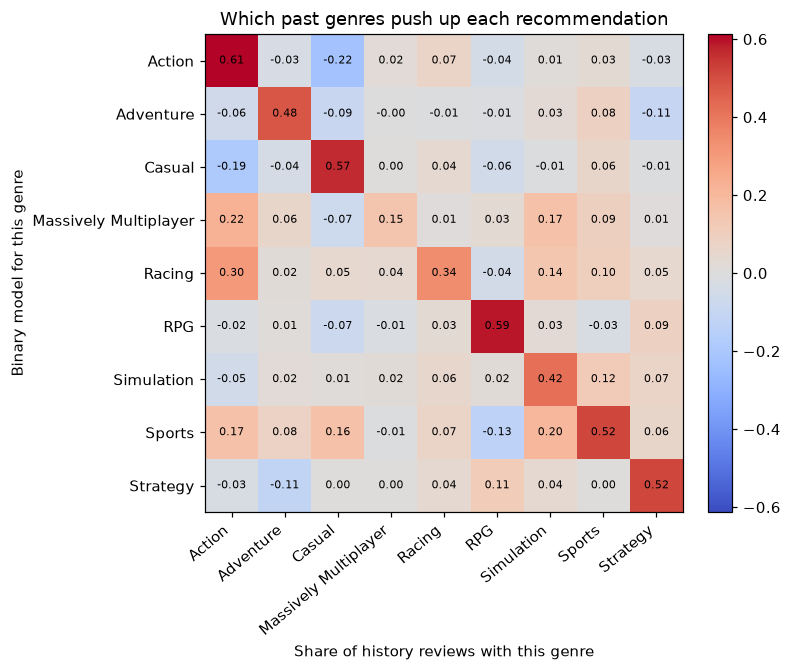

Temporal hit rate: global mode 0.4702, user mode 0.5797, logistic 0.5801, logistic, balanced 0.5079, item-item 0.5725, item-item + user 0.5954, bpr 0.4669
Temporal macro recall: global mode 0.1111, user mode 0.1690, logistic 0.1687, logistic, balanced 0.2356, item-item 0.1666, item-item + user 0.1851, bpr 0.1138
Item-item on temporal: 48,309 games have a later training review, and 92.4% of users receive a neighborhood score. The rest use user mode.
Item-item on random: 49,278 games have a later training review, and 91.8% of users receive a neighborhood score. The rest use user mode.
Item-item on calendar: 28,450 games have a later training review, and 78.9% of users receive a neighborhood score. The rest use user mode.
BPR on temporal: 100.0% of users receive a genre vote from the top 20 unseen games.
BPR on random: 100.0% of users receive a genre vote from the top 20 unseen games.
BPR on calendar: 100.0% of users receive a genre vote from the top 20 unseen games.
Default logistic minu

In [5]:
def genre_counts(idx):
    return genre_mat[np.asarray(idx)].sum(axis=0)


def predict_modes(split):
    combined = np.concatenate(split["histories"])
    global_counts = genre_counts(combined)
    global_genre = choose_global(global_counts)
    user_pred = np.empty(len(split["histories"]), dtype=np.int32)
    for row, hist in enumerate(split["histories"]):
        user_pred[row] = choose_user(genre_counts(hist), global_counts)
    global_pred = np.full(len(split["histories"]), global_genre, dtype=np.int32)
    return global_pred, user_pred, global_genre, global_counts


def fit_logistic(split, class_weight):
    scaler = StandardScaler()
    train_x = scaler.fit_transform(split["train_x"])
    test_x = scaler.transform(split["test_x"])
    clf = OneVsRestClassifier(
        LogisticRegression(
            max_iter=400,
            solver="lbfgs",
            class_weight=class_weight,
            random_state=256,
        ),
        n_jobs=1,
    )
    clf.fit(train_x, split["train_multi"])
    pred = clf.predict_proba(test_x).argmax(axis=1).astype(np.int32)
    return pred, clf


def score_predictions(split, pred):
    test_masks = masks[split["test_positions"]]
    hit = (test_masks & (1 << pred)) != 0
    set_size = np.array([int(value).bit_count() for value in test_masks], dtype=np.int32)
    jaccard = np.where(hit, 1.0 / set_size, 0.0)
    recalls = []
    supports = []
    for genre_i in range(9):
        has = (test_masks & (1 << genre_i)) != 0
        supports.append(int(has.sum()))
        recalls.append(float((pred[has] == genre_i).mean()) if has.any() else np.nan)
    return {
        "hit_rate": float(hit.mean()),
        "mean_jaccard": float(jaccard.mean()),
        "macro_recall": float(np.nanmean(recalls)),
        "recalls": recalls,
        "supports": supports,
        "hit": hit,
        "n_hist": split["n_hist"],
    }


appids = work["appid"].to_numpy()


def build_next_genre_votes(split):
    """Genre distribution of the next gameplay-genre review after each game.

    Pairs come only from reviews inside training histories, ordered by time.
    The held-out review is not in those histories.
    """
    votes = {}
    for hist in split["histories"]:
        if hist.size < 2:
            continue
        order = hist[np.argsort(ts[hist], kind="mergesort")]
        for i in range(order.size - 1):
            nxt = None
            for j in range(i + 1, order.size):
                candidate = genre_mat[order[j]]
                if candidate.sum() > 0:
                    nxt = candidate
                    break
            if nxt is None:
                continue
            src = int(appids[order[i]])
            bucket = votes.get(src)
            if bucket is None:
                bucket = np.zeros(9, dtype=np.float64)
                votes[src] = bucket
            bucket += nxt
    for bucket in votes.values():
        total = bucket.sum()
        if total > 0:
            bucket /= total
    return votes


def predict_item_item(split, user_pred, global_counts, neighbor_weight=0.5):
    """Pure neighbor score, and the same score added at half weight to the user distribution.

    Half weight is a fixed choice: the neighbor distribution sums to 1, and so does the
    user's own genre distribution, so a weight below 1 cannot overturn a one-genre history.
    """
    votes = build_next_genre_votes(split)
    pure = np.empty(len(split["histories"]), dtype=np.int32)
    damped = np.empty(len(split["histories"]), dtype=np.int32)
    n_fallback = 0
    for row, hist in enumerate(split["histories"]):
        order = hist[np.argsort(ts[hist], kind="mergesort")]
        neighbor = np.zeros(9, dtype=np.float64)
        for rank, pos in enumerate(order, start=1):
            bucket = votes.get(int(appids[pos]))
            if bucket is None:
                continue
            neighbor += rank * bucket
        user_counts = genre_counts(hist)
        if neighbor.sum() == 0:
            pure[row] = user_pred[row]
            damped[row] = user_pred[row]
            n_fallback += 1
            continue
        pure[row] = choose_user(neighbor, global_counts)
        blended = neighbor / neighbor.sum() * neighbor_weight
        if user_counts.sum() > 0:
            blended = blended + user_counts / user_counts.sum()
        damped[row] = choose_user(blended, global_counts)
    return pure, damped, n_fallback, len(votes)



def predict_bpr(split, user_pred, global_counts, topn=20):
    """Map a BPR ranking of unseen games onto one gameplay genre."""
    n_users = len(split["histories"])
    row_idx = []
    col_apps = []
    mask_of = {}
    for user_i, hist in enumerate(split["histories"]):
        for pos in hist:
            app = int(appids[pos])
            row_idx.append(user_i)
            col_apps.append(app)
            mask_of[app] = int(masks[pos])
    uniq, col_idx = np.unique(col_apps, return_inverse=True)
    liked = csr_matrix(
        (np.ones(len(row_idx), dtype=np.float32), (np.asarray(row_idx), col_idx)),
        shape=(n_users, len(uniq)),
    )
    liked.sum_duplicates()
    model = BayesianPersonalizedRanking(
        factors=64,
        learning_rate=0.01,
        regularization=0.01,
        iterations=50,
        verify_negative_samples=False,
        random_state=256,
    )
    model.fit(liked, show_progress=False)
    rec_items, rec_scores = model.recommend(
        np.arange(n_users),
        liked,
        N=topn,
        filter_already_liked_items=True,
    )
    pred = np.empty(n_users, dtype=np.int32)
    n_fallback = 0
    for user_i in range(n_users):
        score = np.zeros(9, dtype=np.float64)
        for item_i, conf in zip(rec_items[user_i], rec_scores[user_i]):
            if conf <= 0:
                continue
            mask = mask_of.get(int(uniq[int(item_i)]), 0)
            if mask == 0:
                continue
            for genre_i in range(9):
                if mask & (1 << genre_i):
                    score[genre_i] += float(conf)
        if score.sum() == 0:
            pred[user_i] = user_pred[user_i]
            n_fallback += 1
        else:
            pred[user_i] = choose_user(score, global_counts)
    return pred, n_fallback


def history_slice_mask(n_hist, label):
    if label == "1":
        return n_hist == 1
    if label == "2-4":
        return (n_hist >= 2) & (n_hist <= 4)
    return n_hist >= 5


print("Fitting models.")
model_predictions = {}
global_names = {}
item_item_notes = {}
bpr_notes = {}
for protocol, split in splits.items():
    print(f"  {protocol}: modes")
    global_pred, user_pred, global_genre, global_counts = predict_modes(split)
    print(f"  {protocol}: logistic regression")
    logistic_pred, logistic_clf = fit_logistic(split, class_weight=None)
    print(f"  {protocol}: balanced logistic regression")
    balanced_pred, balanced_clf = fit_logistic(split, class_weight="balanced")
    print(f"  {protocol}: item-item")
    item_pred, damped_pred, n_fallback, n_games = predict_item_item(split, user_pred, global_counts)
    print(f"  {protocol}: bpr")
    bpr_pred, bpr_fallback = predict_bpr(split, user_pred, global_counts)
    bpr_notes[protocol] = {"fallback_users": bpr_fallback, "users": len(user_pred)}
    item_item_notes[protocol] = {
        "fallback_users": n_fallback,
        "users": len(user_pred),
        "games_with_a_next_review": n_games,
    }
    model_predictions[protocol] = {
        "global mode": global_pred,
        "user mode": user_pred,
        "logistic": logistic_pred,
        "logistic, balanced": balanced_pred,
        "item-item": item_pred,
        "item-item + user": damped_pred,
        "bpr": bpr_pred,
    }
    global_names[protocol] = GAMEPLAY[global_genre]
    if protocol == "temporal":
        temporal_clf = logistic_clf
        temporal_global_counts = global_counts

rows = []
scored = {}
for protocol, preds in model_predictions.items():
    for model_name, pred in preds.items():
        metrics = score_predictions(splits[protocol], pred)
        scored[(protocol, model_name)] = metrics
        rows.append({
            "protocol": protocol,
            "model": model_name,
            "users": len(pred),
            "hit_rate": metrics["hit_rate"],
            "macro_recall": metrics["macro_recall"],
            "mean_jaccard": metrics["mean_jaccard"],
        })
comparison = pd.DataFrame(rows)
print("Global mode genre by protocol:", ", ".join(f"{k} = {v}" for k, v in global_names.items()))
print("Temporal training-history counts. A review adds one to each gameplay genre it carries.")
display(pd.Series(temporal_global_counts, index=GAMEPLAY).astype(int).rename("training_reviews").reset_index().rename(columns={"index": "genre"}))
display(comparison.round({"hit_rate": 4, "macro_recall": 4, "mean_jaccard": 4}))

slice_rows = []
for model_name, pred in model_predictions["temporal"].items():
    metrics = scored[("temporal", model_name)]
    for label in ("1", "2-4", "5+"):
        selected = history_slice_mask(metrics["n_hist"], label)
        slice_rows.append({
            "history_reviews": label,
            "model": model_name,
            "users": int(selected.sum()),
            "hit_rate": float(metrics["hit"][selected].mean()),
        })
print("Temporal holdout, hit rate by length of the earlier-review history.")
display(pd.DataFrame(slice_rows).round({"hit_rate": 4}))

recall_frame = {"genre": GAMEPLAY, "test_games": scored[("temporal", "global mode")]["supports"]}
for model_name in model_predictions["temporal"]:
    recall_frame[model_name] = scored[("temporal", model_name)]["recalls"]
recall_table = pd.DataFrame(recall_frame)
print("Temporal holdout, recall among test games that include the genre.")
display(recall_table.round(3))

multi_share = np.mean([int(value).bit_count() >= 2 for value in masks[temporal["test_positions"]]])
print(f"Share of temporal test games with 2 or more gameplay genres: {multi_share:.1%}.")

coef = np.vstack([est.coef_.ravel() for est in temporal_clf.estimators_])
coef_table = pd.DataFrame(coef, index=GAMEPLAY, columns=FEATURE_NAMES)
print("Temporal logistic regression, default class weights. Rows are the nine binary models.")
display(coef_table.round(3))

block = coef[:, :9]
limit = float(np.max(np.abs(block)))
fig, ax = plt.subplots(figsize=(7.6, 6.2))
im = ax.imshow(block, cmap="coolwarm", vmin=-limit, vmax=limit)
ax.set_xticks(range(9), GAMEPLAY, rotation=40, ha="right")
ax.set_yticks(range(9), GAMEPLAY)
ax.set_xlabel("Share of history reviews with this genre")
ax.set_ylabel("Binary model for this genre")
ax.set_title("Which past genres push up each recommendation")
for row in range(9):
    for col in range(9):
        ax.text(col, row, f"{block[row, col]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()

temporal_table = comparison.loc[comparison["protocol"].eq("temporal")].set_index("model")
print("Temporal hit rate: " + ", ".join(
    f"{name} {temporal_table.loc[name, 'hit_rate']:.4f}" for name in temporal_table.index
))
print("Temporal macro recall: " + ", ".join(
    f"{name} {temporal_table.loc[name, 'macro_recall']:.4f}" for name in temporal_table.index
))
for protocol, note in item_item_notes.items():
    covered = 1 - note["fallback_users"] / note["users"]
    print(
        f"Item-item on {protocol}: {note['games_with_a_next_review']:,} games have a later training review, "
        f"and {covered:.1%} of users receive a neighborhood score. The rest use user mode."
    )
gap = temporal_table.loc["logistic", "hit_rate"] - temporal_table.loc["user mode", "hit_rate"]
rec = recall_table.set_index("genre")
for protocol, note in bpr_notes.items():
    covered = 1 - note["fallback_users"] / note["users"]
    print(f"BPR on {protocol}: {covered:.1%} of users receive a genre vote from the top 20 unseen games.")
print(f"Default logistic minus user mode on the temporal hit rate is {gap:+.4f}.")
print(
    f"On temporal test games that include Action, logistic recall is {rec.loc['Action', 'logistic']:.3f} "
    f"and user-mode recall is {rec.loc['Action', 'user mode']:.3f}. "
    f"On games that include Adventure, logistic recall is {rec.loc['Adventure', 'logistic']:.3f} "
    f"and user-mode recall is {rec.loc['Adventure', 'user mode']:.3f}."
)
print("The balanced fit is the one that spends hit rate to raise recall on Massively Multiplayer, Racing, and Sports.")
blend_gap = temporal_table.loc["item-item + user", "hit_rate"] - temporal_table.loc["user mode", "hit_rate"]
print(
    f"Neighbor distribution alone, temporal hit rate {temporal_table.loc['item-item', 'hit_rate']:.4f}. "
    f"Added at half weight on top of the user distribution, {temporal_table.loc['item-item + user', 'hit_rate']:.4f} "
    f"({blend_gap:+.4f} versus user mode)."
)
print(
    f"Random-split user mode hit rate is {scored[('random', 'user mode')]['hit_rate']:.4f} "
    f"on {len(random_split['test_positions']):,} users. "
    f"Temporal user mode hit rate is {scored[('temporal', 'user mode')]['hit_rate']:.4f} "
    f"on {len(temporal['test_positions']):,} users. "
    "The random protocol may read reviews written after the held-out one, and it does not always hold out the latest review."
)
print(
    f"Calendar user mode hit rate is {scored[('calendar', 'user mode')]['hit_rate']:.4f} "
    f"on {len(calendar['test_positions']):,} users, those with a game review on both sides of {cutoff_time.date()}."
)


## What the numbers can support

Hit rate asks whether the one named genre is attached to the held-out game. Many of those games carry two or more gameplay genres, so a hit is easier than naming the game's whole set. Mean Jaccard is lower for that reason: a correct name on a three-genre game scores one third.

Global mode names a single genre for every user: whichever gameplay genre is most common on the training histories. Action and Adventure are close in the full catalog, and the training-history counts printed with the model table are the ones the baseline uses. User mode names the genre that user has already reviewed most often. With one earlier review, user mode can only repeat a genre of that game, which is why the history-length table matters. The default logistic regression stays next to user mode on hit rate. The per-genre recall table shows that the two predictors still catch different genres. The diagonal of the coefficient figure is the direct effect: a history full of Racing reviews raises the Racing model.

The balanced class weights give Racing, Sports, and Massively Multiplayer more influence inside each binary problem. That raises per-genre recall and spends hit rate. Neither fit is a search over hyperparameters.

The neighbor model is the one that uses the game id. Using it instead of the user's genres lowers the temporal hit rate. Adding it at half weight on top of those genres raises the temporal hit rate, including for users whose history is a single review. That review usually carries more than one gameplay genre, and the neighbors choose among those genres. A one-genre history is left as it is, because the neighbor term is only half a distribution. On the calendar split the same blend does not improve on user mode. The balanced logistic regression remains the model with the higher macro recall.

The random protocol is the one that ignores time. It holds out a random gameplay-genre review rather than the latest one, and its history may include reviews written later. It also keeps a few users the temporal rule drops, namely users whose only earlier material comes after their gameplay-genre review. The calendar protocol keeps time. Because the year chart is dominated by 2025, the 80th percentile falls in the last weeks of the file, and the users who remain are those with a sampled review on both sides of that late cutoff. Its hit rate is not a score on the same people as the temporal table.

The sample is about ten reviews per application. A user's mode in this file is the mode of the reviews that happened to be drawn, which is a noisy stand-in for the mode of their library. The lexicon that makes the nine labels possible is a hand map; the Russian multiplayer string, RYO, Rol, and the unmapped Arabic tag are recorded in cursor_notes/genre_lexicon.md. BPR factorizes the training user-game pairs and names a genre from the top 20 unseen games. On the temporal holdout its hit rate is 0.466, beside global mode at 0.470. Its per-genre recall is 0.879 on Adventure and 0.148 on Casual, and zero on the other seven genres, so the ranking is selecting popular games. Users with five or more earlier reviews still score 0.477. The half-weight item-item model remains the highest temporal hit rate, at 0.595. Review text is still unused.
